## Optimizing the MLP using Normalization Techniques: Batch Normalization

In [ ]:
import random
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [ ]:
words = open('names.txt', 'r').read().splitlines()

In [ ]:
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s, i in stoi.items()}
vocab_size = len(itos)
print(itos)
print(vocab_size)

In [ ]:
block_size = 3

def build_datset(words):
    x, y = [], []

    for w in words:
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            x.append(context)
            y.append(ix)
            context = context[1:] + [ix]

    X = torch.tensor(x)
    Y = torch.tensor(y)
    print(X.shape, Y.shape)
    return X, Y

random.seed(42)
random.shuffle(words)
n1 = (0.8 * len(words))
n2 = (0.9 * len(words))

Xtr, Ytr = build_datset(words[:n1])
Xdev, Ydev = build_datset(words[n1:n2])
Xte, Yte = build_datset(words[n2:])

In [ ]:
n_emb = 5
n_hidden = 200

# parameters
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_emb), generator=g, requires_grad=True)
W1 = torch.randn((n_emb*block_size, n_hidden), generator=g, requires_grad=True) * (5/3) / ((n_emb*block_size)**0.5) #* 0.2 
# to bring tanh value closure to zero
# b1 = torch.randn(n_hidden, generator=g, requires_grad=True) * 0.01 
# to bring tanh value closure to zero
W2 = torch.randn((n_hidden, vocab_size), generator=g, requires_grad=True) * 0.01 
# to fix initialization error
b2 = torch.randn(vocab_size, generator=g, requires_grad=True) * 0 
# to fix initialization error

# batch normalization params
# affine params
bngain = torch.ones((1, n_hidden), requires_grad=True)
bnbias = torch.zeroes((1, n_hidden), requires_grad=True)
# track_running_stats
bnmean_running = torch.zeroes((1, n_hidden), requires_grad=True)
bnstd_running = bnbias = torch.ones((1, n_hidden), requires_grad=True)

parameters = [C, W1, b1, W2, b2, bngain, bnbias]
print(sum(p.nelement() for p in parameters))

Two Issues to fix -
1. Initialization Loss
- At initialization each letter has varying prob. but we don't want that, the first character should have near zero or same prob.
- That is why we multiply b2 with 0 and W2 with a small num like 0.01. 
- We don't multiply W2 with 0

2. Saturated tanh
- hpreact values are between -15 and 15 so all of them are being being squashed between -1 and 1 by tanh. The values in the extreme/flat rgion become -1 and 1 and so most values are either -1 or 1.
- For -1 and 1 the gradient basicaaly vanishes during backprop.
- Also values that become 0 the out.grad just passes through tanh, i.e., the tanh unit inactive.
- So the amount of gradient passing through tanh can only decrease. This decrease is proportionla to the sqaure.

### Dead Neuron
- when regardless of the input the tanh unit outputs either 1 or -1. In this case th eneuron doesn't learn, grad is zero.

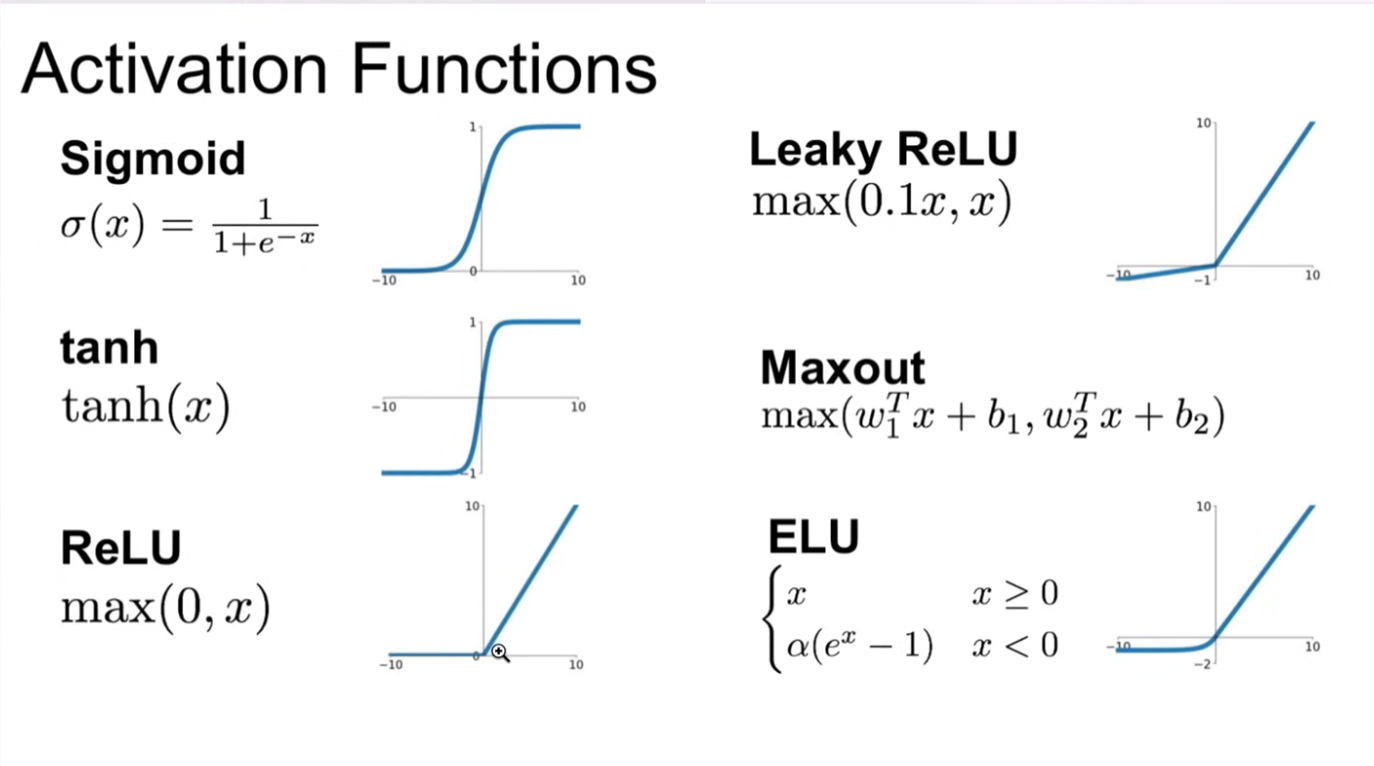

In [ ]:
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):
    # mini batches
    ix = torch.randn(0, Xtr.shape[0], (batch_size,))
    Xb, Yb = Xtr[ix], Ytr[ix]

    # forward pass
    emb = C[Xb]
    embcat = emb.view(emb.shape[0], -1)
    # the bias b1 is useless as it gets substracted below (hpreact-bnmeani) and so adding it is pointless. Also th hidden layer has ots own bias during batch normalization
    # Linear layer
    hpreact = embcat @ W1 #+ b1

    # Batch Norm Layer
#------------------------------------------------------------------------------------
    # applied batch normalization to ensure that the activation is guasian at least at initialization
    bnmeani = hpreact.mean(0, keepdim = True)
    bnstdi = hpreact.std(0, keepdim =True)
    hpreact = bngain * ((hpreact - bnmeani) / bnstdi) + bnbias
    # calibrating the batch mean and std along training, instead of doing it afterwards
    with torch.no_grad():
        bnmean_running = 0.999 * bnmean_running + 0.001 * bnmeani # 0.001 is called momentum ->this value depends on the batch size
        bnstd_running = 0.999 * bnstd_running + 0.001 * bnstdi
#------------------------------------------------------------------------------------

    h = torch.tanh(hpreact)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Yb)

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01
    for p in parameters:
        p.data += -lr * p.grad

    # Track stats
    if i % 10000 == 0:
        print(f"{1:7d}/{max_steps:7d}: {loss.item():4f}")
    lossi.append(loss.log10().item())

print(loss.items())

IndentationError: expected an indented block after 'with' statement on line 19 (1339266729.py, line 20)

In [ ]:
plt.plot(lossi)


## loss log
#### original:
train 2.1245384216308594 val 2.168196439743042

#### fix softmax confidently wrong:
train 2.07 val 2.13

#### fix tanh layer too saturated at init:
train 2.0355966091156006 val 2.1026785373687744

#### use semi-principled "kaiming init" instead of hacky init:
train 2.0376641750335693 val 2.106989622116089

#### add batch norm layer
train 2.0668270587921143 val 2.104844808578491

## torch.nn.init -> kaiming init
- instead of using magic numbers (0.2, 0.1) to compensate for the squashing function and maintaining the standard deviation we noramlize the weights with gain/(square root of fan_in).
- fan_in is the number of inputs

## Batch Normalization
- this is one of the modern initialization techniques used in place of the gain/fan_in method
- the epsilon is a very small number preventing division by zero only

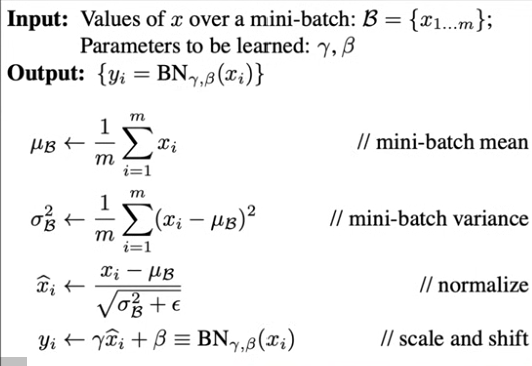

In [ ]:
# calibrate the batch norm at the end of training

with torch.no_grad():
    emb = C[Xtr]
    embcat = emb.view(emb.shape[0],-1)
    hpreact = embcat @ W1 # + b1

    bnmean = hpreact.mean(0, keepdim = True)
    bnstd = hpreact.mean(0, keepdim = True)

In [ ]:
@torch.no_grad() # this decorator disables gradient tracking
def split_loss(split):
  x,y = {
    'train': (Xtr, Ytr),
    'val': (Xdev, Ydev),
    'test': (Xte, Yte),
  }[split]
  emb = C[x] # (N, block_size, n_embd)
  embcat = emb.view(emb.shape[0], -1) # concat into (N, block_size * n_embd)
  hpreact = embcat @ W1 # + b1
  #hpreact = bngain * (hpreact - hpreact.mean(0, keepdim=True)) / hpreact.std(0, keepdim=True) + bnbias
  hpreact = bngain * (hpreact - bnmean_running) / bnstd_running + bnbias
  h = torch.tanh(hpreact) # (N, n_hidden)
  logits = h @ W2 + b2 # (N, vocab_size)
  loss = F.cross_entropy(logits, y)
  print(split, loss.item())

split_loss('train')
split_loss('val')

In [ ]:
# sample from the model
g = torch.Generator().manual_seed(2147483647)

for _ in range(20):
    out = []
    context = [0] * block_size

    while True:
        emb = C[torch.tensor([context])]
        h = torch.tanh(emb.view(-1, 12) @ W1) # + b1
        logits = h @ W2 + b2
        probs = F.softmax(logits, dim=1)

        ix = torch.multinomial(probs, num_samples=1, replacement=True, generator=g).items()
        context = context[1:] + ix
        out.append(ix)
        if ix==0:
            break

    print(''.join(itos[i] for i in out))

In [ ]:
''' 
Resonets -> residual NN, common neural networks used for image classification.
It consists of block stacked up sequencially
The block is called Bottleneck block
'''

### PyTorchifying

In [ ]:
class Linear:
    def __init__():

    def __call__(self, *args, **kwds):


    def parameters(self):


class BatchNorm1d:
    def __init__():

    def 